# 13. Ostrzejszy obraz czas–częstotliwość

**Arkadiusz Liber** · *Falki w praktyce. Od wzoru do kodu*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/writingin/falki-w-praktyce-od-wzoru-do-kodu-notatniki/blob/main/rozdzial-13.ipynb)

Notatnik do książki. Zawiera wszystkie programy z tekstu rozdziału oraz ćwiczenia z rozwiązaniami.

Notatnik działa lokalnie (Jupyter) i w Google Colab. Komórki można uruchamiać po kolei poleceniem *Uruchom wszystko*.

In [1]:
# Uruchom tę komórkę jako pierwszą (lokalnie albo w Google Colab).
import sys, subprocess, importlib.util, os
if importlib.util.find_spec("pywt") is None:      # PyWavelets
    subprocess.check_call([sys.executable, "-m", "pip",
                           "install", "-q", "PyWavelets"])
import numpy as np
import matplotlib.pyplot as plt
import pywt

SZARY, NIEBIESKI, RDZAWY, ZIELONY = "#757575", "#1273E2", "#D93B0B", "#078832"
FIOLET, BURSZTYN = "#9258D5", "#B36000"
plt.rcParams.update({
    "text.color": SZARY, "axes.labelcolor": SZARY, "axes.edgecolor": SZARY,
    "xtick.color": SZARY, "ytick.color": SZARY, "axes.titlecolor": SZARY,
    "font.size": 10, "axes.titlesize": 10,
    "axes.spines.top": False, "axes.spines.right": False})


## Programy z tekstu rozdziału

### Kod 13.1. Transformata ciągła liczona przez FFT: falki Morse'a i falka Morleta

In [2]:
import numpy as np

def morse(omega, beta=20.0, gamma=3.0):
    """Widmo uogólnionej falki Morse'a; maksimum równe 2."""
    wp = (beta/gamma)**(1/gamma)               # pulsacja maksimum
    w = np.where(omega > 0, omega, wp)
    widmo = 2*np.exp(beta*np.log(w/wp) - w**gamma + wp**gamma)
    return np.where(omega > 0, widmo, 0.0)

def cwt(x, fs, czest, beta=20.0, gamma=3.0):
    """CWT w normalizacji amplitudowej, wzór (13.2)."""
    X = np.fft.fft(x)
    omega = 2*np.pi*np.fft.fftfreq(len(x))     # [rad/próbkę]
    wp = (beta/gamma)**(1/gamma)
    skale = wp*fs/(2*np.pi*np.asarray(czest))  # [próbki]
    return np.array([np.fft.ifft(X*morse(a*omega, beta, gamma))
                     for a in skale])

fs = 200
t = np.arange(0, 8, 1/fs)
s = 1.5*np.cos(2*np.pi*10*t) + 4.0             # sinusoida i stała
srodek = slice(400, -400)
for beta in (1, 3, 20):
    W = np.abs(cwt(s, fs, [10.0], beta)[0, srodek])
    print(f"Morse'a, beta = {beta:2d}: |W| od {W.min():.4f} "
          f"do {W.max():.4f}")

# falka Morleta o pulsacji środkowej w0 w tym samym unormowaniu
X, omega = np.fft.fft(s), 2*np.pi*np.fft.fftfreq(len(s))
for w0 in (1.73, 3.0, 6.0):
    a = w0*fs/(2*np.pi*10)
    W = np.abs(np.fft.ifft(X*2*np.exp(-(a*omega - w0)**2/2))[srodek])
    print(f"Morleta, w0 = {w0:4.2f}: |W| od {W.min():.4f} "
          f"do {W.max():.4f}")

Morse'a, beta =  1: |W| od 1.5000 do 1.5000
Morse'a, beta =  3: |W| od 1.5000 do 1.5000
Morse'a, beta = 20: |W| od 1.5000 do 1.5000
Morleta, w0 = 1.73: |W| od 0.2876 do 3.2952
Morleta, w0 = 3.00: |W| od 1.4111 do 1.5889
Morleta, w0 = 6.00: |W| od 1.5000 do 1.5000


### Kod 13.2. Własności falek Morse'a wyznaczone numerycznie

In [3]:
import numpy as np

def morse(omega, beta=20.0, gamma=3.0):
    wp = (beta/gamma)**(1/gamma)
    w = np.where(omega > 0, omega, wp)
    widmo = 2*np.exp(beta*np.log(w/wp) - w**gamma + wp**gamma)
    return np.where(omega > 0, widmo, 0.0)

N = 2**14
omega = 2*np.pi*np.fft.fftfreq(N)
n = np.arange(N) - N//2
f0 = 0.05                                  # maksimum widma [cykle/próbkę]
print(" beta gamma     P  sigma_t*sigma_w  cykle  f_sr/f_max")
for beta, gamma in ((1, 3), (3, 3), (20, 3), (60, 3),
                    (9, 1), (4.5, 2), (2.25, 4)):
    wp = (beta/gamma)**(1/gamma)
    Psi = morse(wp/(2*np.pi*f0)*omega, beta, gamma)
    psi = np.fft.fftshift(np.fft.ifft(Psi))        # falka w czasie
    p = np.abs(psi)**2/np.sum(np.abs(psi)**2)
    q = Psi**2/np.sum(Psi**2)
    sigma_t = np.sqrt(np.sum(n**2*p) - np.sum(n*p)**2)
    srednia = np.sum(omega*q)
    sigma_w = np.sqrt(np.sum(omega**2*q) - srednia**2)
    print(f"{beta:5} {gamma:5} {np.sqrt(beta*gamma):5.2f} "
          f"{sigma_t*sigma_w:12.4f} {2*sigma_t*f0:9.2f} "
          f"{srednia/(2*np.pi*f0):9.3f}")

 beta gamma     P  sigma_t*sigma_w  cykle  f_sr/f_max
    1     3  1.73       0.5313      0.46     1.022
    3     3  3.00       0.5014      0.70     1.003
   20     3  7.75       0.5000      1.75     1.000
   60     3 13.42       0.5000      3.02     1.000
    9     1  3.00       0.5286      0.69     1.056
  4.5     2  3.00       0.5086      0.70     1.028
 2.25     4  3.00       0.5041      0.70     0.979


### Kod 13.3. Wskaźnik El Niño: okresy i epizody o największej mocy

In [4]:
import numpy as np
import pywt

def morse(omega, beta=20.0, gamma=3.0):
    wp = (beta/gamma)**(1/gamma)
    w = np.where(omega > 0, omega, wp)
    widmo = 2*np.exp(beta*np.log(w/wp) - w**gamma + wp**gamma)
    return np.where(omega > 0, widmo, 0.0)

def cwt(x, fs, czest, beta=20.0, gamma=3.0):
    X = np.fft.fft(x)
    omega = 2*np.pi*np.fft.fftfreq(len(x))
    wp = (beta/gamma)**(1/gamma)
    skale = wp*fs/(2*np.pi*np.asarray(czest))
    return np.array([np.fft.ifft(X*morse(a*omega, beta, gamma))
                     for a in skale])

lata, sst = pywt.data.nino()               # 264 wartości kwartalne
fs = 4.0                                   # próbki na rok
x = np.concatenate([sst - sst.mean(), np.zeros(512 - len(sst))])
okresy = np.geomspace(0.75, 16, 133)       # [lata]
for beta in (3, 10, 30):
    moc = np.abs(cwt(x, fs, 1/okresy, beta)[:, :len(sst)])**2
    widmo = moc.mean(axis=1)
    pasmo = (okresy >= 2) & (okresy <= 7)
    szczyt = okresy[pasmo][np.argmax(widmo[pasmo])]
    w_pasmie = moc[pasmo].mean(axis=0)
    epizody = []
    for k in np.argsort(w_pasmie)[::-1]:   # od najsilniejszych
        if all(abs(lata[k] - e) > 4 for e in epizody):
            epizody.append(float(lata[k]))
        if len(epizody) == 4:
            break
    print(f"beta = {beta:2d}: okres roczny {okresy[np.argmax(widmo)]:.2f}"
          f", szczyt w pasmie 2–7 lat: {szczyt:.1f} roku, "
          f"epizody: {sorted(epizody)}")

beta =  3: okres roczny 1.01, szczyt w pasmie 2–7 lat: 3.4 roku, epizody: [1972.5, 1983.0, 1987.75, 1997.75]
beta = 10: okres roczny 0.99, szczyt w pasmie 2–7 lat: 3.5 roku, epizody: [1972.5, 1983.25, 1987.5, 1997.75]
beta = 30: okres roczny 0.99, szczyt w pasmie 2–7 lat: 3.6 roku, epizody: [1972.75, 1985.5, 1989.75, 1997.5]


### Kod 13.4. Synchrosqueezing: skupienie energii i wydzielanie składowych

In [5]:
import numpy as np
from math import lgamma

def morse(omega, beta=20.0, gamma=3.0):
    wp = (beta/gamma)**(1/gamma)
    w = np.where(omega > 0, omega, wp)
    widmo = 2*np.exp(beta*np.log(w/wp) - w**gamma + wp**gamma)
    return np.where(omega > 0, widmo, 0.0)

def synchro(x, fs, czest, beta=20.0, gamma=3.0, prog=1e-3):
    """Zwraca CWT i transformatę ściśniętą (czest: siatka logarytmiczna)."""
    X = np.fft.fft(x)
    omega = 2*np.pi*np.fft.fftfreq(len(x))
    wp = (beta/gamma)**(1/gamma)
    W = np.empty((len(czest), len(x)), complex)
    dW = np.empty_like(W)
    for i, f in enumerate(czest):
        Y = X*morse(wp*fs/(2*np.pi*f)*omega, beta, gamma)
        W[i], dW[i] = np.fft.ifft(Y), np.fft.ifft(1j*omega*Y)
    krok = np.log(czest[1]/czest[0])
    silne = np.abs(W) > prog*np.abs(W).max()
    f_chw = np.ones(W.shape)               # częstotliwość chwilowa (13.6)
    f_chw[silne] = fs*np.imag(dW[silne]/W[silne])/(2*np.pi)
    k = np.rint(np.log(np.maximum(f_chw, 1e-9)/czest[0])/krok).astype(int)
    dobre = silne & (k >= 0) & (k < len(czest))
    kol = np.broadcast_to(np.arange(len(x)), W.shape)
    T = np.zeros_like(W)
    np.add.at(T, (k[dobre], kol[dobre]), W[dobre])   # przeniesienie (13.7)
    C = 2*np.exp(wp**gamma - beta*np.log(wp) + lgamma(beta/gamma))/gamma
    return W, T*2*krok/C

fs = 400
t = np.arange(0, 6, 1/fs)
f1 = 10 + 5*t                              # częstotliwości chwilowe
f2 = 120 + 30*np.sin(2*np.pi*0.25*t)
s1 = np.cos(2*np.pi*np.cumsum(f1)/fs)
s2 = 0.7*np.cos(2*np.pi*np.cumsum(f2)/fs)
czest = np.geomspace(5, 195, 240)
krok = np.log(czest[1]/czest[0])
kolumny, srodek = np.arange(t.size), slice(200, -200)

def pasmo(M, f, d):
    """Suma wierszy macierzy M w pasie ±d wierszy wokół krzywej f(t)."""
    k0 = np.rint(np.log(f/czest[0])/krok).astype(int)
    return sum(M[np.clip(k0 + j, 0, len(czest) - 1), kolumny]
               for j in range(-d, d + 1))

rng = np.random.default_rng(0)
for sigma in (0.0, 0.3):
    x = s1 + s2 + sigma*rng.normal(size=t.size)
    W, T = synchro(x, fs, czest)
    udzial = [(pasmo(np.abs(M)**2, f1, 2) + pasmo(np.abs(M)**2, f2, 2))
              [srodek].sum()/(np.abs(M[:, srodek])**2).sum()
              for M in (W, T)]
    blad = lambda y, s: (np.linalg.norm((y - s)[srodek])
                         / np.linalg.norm(s[srodek]))
    print(f"sigma = {sigma}: energia w pasie ±2 wierszy: CWT "
          f"{100*udzial[0]:.0f}%, po ściśnięciu {100*udzial[1]:.0f}%")
    print(f"   błąd odtworzenia: całość "
          f"{100*blad(T.sum(axis=0).real, x):.1f}%, składowa 1 "
          f"{100*blad(pasmo(T, f1, 6).real, s1):.1f}%, składowa 2 "
          f"{100*blad(pasmo(T, f2, 6).real, s2):.1f}%")

sigma = 0.0: energia w pasie ±2 wierszy: CWT 32%, po ściśnięciu 100%
   błąd odtworzenia: całość 1.3%, składowa 1 0.0%, składowa 2 2.3%
sigma = 0.3: energia w pasie ±2 wierszy: CWT 30%, po ściśnięciu 96%
   błąd odtworzenia: całość 7.7%, składowa 1 10.7%, składowa 2 28.8%


### Kod 13.5. Grzbiet skalogramu w silnym szumie: maksimum w kolumnach i programowanie dynamiczne

In [6]:
import numpy as np

def morse(omega, beta=20.0, gamma=3.0):
    wp = (beta/gamma)**(1/gamma)
    w = np.where(omega > 0, omega, wp)
    widmo = 2*np.exp(beta*np.log(w/wp) - w**gamma + wp**gamma)
    return np.where(omega > 0, widmo, 0.0)

def cwt(x, fs, czest, beta=20.0, gamma=3.0):
    X = np.fft.fft(x)
    omega = 2*np.pi*np.fft.fftfreq(len(x))
    wp = (beta/gamma)**(1/gamma)
    skale = wp*fs/(2*np.pi*np.asarray(czest))
    return np.array([np.fft.ifft(X*morse(a*omega, beta, gamma))
                     for a in skale])

def grzbiet(M, kara=0.5, skok=8):
    """Ścieżka o największej sumie log-energii z karą za skoki."""
    E = np.log(np.abs(M)**2 + 1e-12*np.abs(M).max()**2)
    K, T = E.shape
    wiersze = np.arange(K)
    koszt, skad = E[:, 0].copy(), np.zeros((K, T), int)
    for t in range(1, T):
        najlepszy = np.full(K, -np.inf)
        for d in range(-skok, skok + 1):       # przejście z k - d do k
            a, b = max(0, d), min(K, K + d)
            kandydat = np.full(K, -np.inf)
            kandydat[a:b] = koszt[a - d:b - d] - kara*d*d
            lepszy = kandydat > najlepszy
            najlepszy[lepszy] = kandydat[lepszy]
            skad[lepszy, t] = wiersze[lepszy] - d
        koszt = najlepszy + E[:, t]
    sciezka = np.empty(T, int)
    sciezka[-1] = np.argmax(koszt)
    for t in range(T - 1, 0, -1):              # powrót po śladach
        sciezka[t - 1] = skad[sciezka[t], t]
    return sciezka

fs = 400
t = np.arange(0, 6, 1/fs)
f2 = 120 + 30*np.sin(2*np.pi*0.25*t)
s = np.cos(2*np.pi*np.cumsum(f2)/fs)
czest = np.geomspace(5, 195, 240)
srodek = slice(200, -200)
rng = np.random.default_rng(1)
rms = lambda f: np.sqrt(np.mean((f - f2)[srodek]**2))
for sigma in (0.5, 1.0, 2.0):
    W = cwt(s + sigma*rng.normal(size=t.size), fs, czest)
    f_max = czest[np.argmax(np.abs(W), axis=0)]
    f_dyn = czest[grzbiet(W)]
    print(f"sigma = {sigma} (SNR {10*np.log10(0.5/sigma**2):5.1f} dB): "
          f"błąd maksimum {rms(f_max):5.1f} Hz, "
          f"programowanie dynamiczne {rms(f_dyn):5.1f} Hz")

sigma = 0.5 (SNR   3.0 dB): błąd maksimum   2.5 Hz, programowanie dynamiczne   0.9 Hz
sigma = 1.0 (SNR  -3.0 dB): błąd maksimum  23.2 Hz, programowanie dynamiczne   2.8 Hz
sigma = 2.0 (SNR  -9.0 dB): błąd maksimum  40.5 Hz, programowanie dynamiczne  21.4 Hz


### Kod 13.6. Superlety: średnia geometryczna odpowiedzi falek o rosnącej liczbie cykli

In [7]:
import numpy as np

def morlet(x, fs, czest, cykle):
    """Moduł CWT z falką Morleta o zadanej liczbie cykli."""
    X = np.fft.fft(x)
    f = np.fft.fftfreq(len(x), 1/fs)
    S = np.empty((len(czest), len(x)))
    for i, f0 in enumerate(czest):
        sigma_t = cykle/(5*f0)             # odchylenie obwiedni [s]
        okno = 2*np.exp(-2*(np.pi*sigma_t*(f - f0))**2)
        S[i] = np.abs(np.fft.ifft(X*okno))
    return S

def superlet(x, fs, czest, c1=3, rzad=(1, 1)):
    """Rząd rośnie liniowo z częstotliwością od rzad[0] do rzad[1]."""
    r = np.linspace(rzad[0], rzad[1], len(czest))[:, None]
    logS = np.zeros((len(czest), len(x)))
    for i in range(1, int(np.ceil(r.max())) + 1):
        waga = np.clip(r - (i - 1), 0, 1)  # ułamkowy udział i-tej falki
        logS += waga*np.log(morlet(x, fs, czest, c1*i) + 1e-300)
    return np.exp(logS/r)

fs = 1000
t = np.arange(0, 3, 1/fs)
def paczka(f0, t0, cykle=7):
    trwa = (t >= t0) & (t < t0 + cykle/f0)
    return np.where(trwa, np.sin(2*np.pi*f0*(t - t0)), 0.0)

fa, fb, odstep = 50, 60, 4                 # odstęp w cyklach
x = sum(paczka(f, 1.0) + paczka(f, 1.0 + (7 + odstep)/f)
        for f in (fa, fb))
czest = np.linspace(30, 80, 201)
ia, ib = np.argmin(np.abs(czest - fa)), np.argmin(np.abs(czest - fb))
k0 = int((1.0 + 3.5/55)*fs)                # środek pierwszych paczek
k1 = int((1.0 + 3.5/fa)*fs)
k2 = int((1.0 + (7 + odstep + 3.5)/fa)*fs)

def dolki(S):
    """Dołek między paczkami względem niższego ze szczytów (moc)."""
    P = S**2
    w_czest = P[ia:ib, k0].min()/min(P[ia, k0], P[ib, k0])
    w_czasie = P[ia, k1:k2].min()/min(P[ia, k1], P[ia, k2])
    return w_czest, w_czasie

for c in (3, 7, 10, 15, 30):
    d = dolki(morlet(x, fs, czest, c))
    print(f"Morlet, {c:2d} cykli:      częstotliwość {d[0]:.2f}, "
          f"czas {d[1]:.2f}, iloczyn {d[0]*d[1]:.3f}")
for rzad in ((5, 5), (3, 10), (10, 10)):
    d = dolki(superlet(x, fs, czest, 3, rzad))
    print(f"superlet, rząd {rzad[0]:2d}–{rzad[1]:2d}: częstotliwość "
          f"{d[0]:.2f}, czas {d[1]:.2f}, iloczyn {d[0]*d[1]:.3f}")

Morlet,  3 cykli:      częstotliwość 1.00, czas 0.00, iloczyn 0.005
Morlet,  7 cykli:      częstotliwość 0.54, czas 0.21, iloczyn 0.111
Morlet, 10 cykli:      częstotliwość 0.29, czas 0.35, iloczyn 0.103
Morlet, 15 cykli:      częstotliwość 0.16, czas 0.71, iloczyn 0.117
Morlet, 30 cykli:      częstotliwość 0.06, czas 1.01, iloczyn 0.057
superlet, rząd  5– 5: częstotliwość 0.39, czas 0.16, iloczyn 0.062
superlet, rząd  3–10: częstotliwość 0.30, czas 0.20, iloczyn 0.061
superlet, rząd 10–10: częstotliwość 0.17, czas 0.42, iloczyn 0.074


### Kod 13.7. Baza WDM zbudowana z definicji i sprawdzenie ortonormalności

In [8]:
import numpy as np
from scipy.special import betainc

N, Nf = 256, 8                             # próbki, pasma
Nt = N//Nf                                 # położenia w czasie

# widmo okna Meyera na prążkach DFT: A = Nt/8, B = Nt/4 prążków
l = np.fft.fftfreq(N, 1/N)
nu = betainc(4, 4, np.clip((np.abs(l) - Nt/8)/(Nt/4), 0, 1))
Phi = np.sqrt(2*Nf)*np.cos(np.pi/2*nu)
phi = np.fft.ifft(Phi).real                # okno w dziedzinie czasu
print("norma okna:", round(float(np.linalg.norm(phi)), 12),
      " niezerowe prążki widma:", int(np.sum(Phi > 1e-9)), "z", N)

k = np.arange(N)
baza, opis = [], []
for n in range(Nt):
    okno = np.roll(phi, n*Nf)
    for m in range(Nf + 1):
        if m in (0, Nf):                   # pasma skrajne: co drugie n
            if n % 2:
                continue
            g = okno*np.cos(np.pi*m*k/Nf)
        elif (n + m) % 2 == 0:
            g = np.sqrt(2)*(-1)**(n*m)*np.cos(np.pi*m*k/Nf)*okno
        else:
            g = np.sqrt(2)*np.sin(np.pi*m*k/Nf)*okno
        baza.append(g)
        opis.append((n, m))
G = np.array(baza)
print(G.shape, "największe odchylenie od ortonormalności:",
      f"{np.abs(G @ G.T - np.eye(N)).max():.1e}")

x = np.random.default_rng(0).normal(size=N)
w = G @ x                                  # analiza
print(np.allclose(G.T @ w, x), np.isclose(np.sum(w**2), np.sum(x**2)))

norma okna: 1.0  niezerowe prążki widma: 23 z 256
(256, 256) największe odchylenie od ortonormalności: 1.9e-14
True True


### Kod 13.8. Szybka transformata WDM i transformata odwrotna

In [9]:
import numpy as np
from scipy.special import betainc

def okno(Nt, Nf, d=4):
    """Widmo okna Meyera na prążkach l = -Nt/2, …, Nt/2 - 1."""
    l = np.arange(-Nt//2, Nt//2)
    nu = betainc(d, d, np.clip(4*np.abs(l)/Nt - 0.5, 0, 1))
    return np.sqrt(2*Nf)*np.cos(np.pi/2*nu)

def mnozniki(Nt, Nf):
    """Liczby q[n, m]: współczynnik jest częścią rzeczywistą q*y."""
    n, m = np.mgrid[0:Nt, 0:Nf + 1]
    q = np.where((n + m) % 2 == 0, np.sqrt(2)*(-1.0)**(n*m),
                 np.sqrt(2)*1j)
    return np.where((m == 0) | (m == Nf), 1.0*(n % 2 == 0), q)

def wdm(x, Nf):
    """Zwraca tablicę w[n, m]: n – czas, m – pasmo (0 … Nf)."""
    N = len(x); Nt = N//Nf
    l = np.arange(-Nt//2, Nt//2)
    X, Phi = np.fft.fft(x), okno(Nt, Nf)
    y = np.array([np.fft.ifft(np.fft.ifftshift(
        X[(l + m*Nt//2) % N]*Phi)) for m in range(Nf + 1)]).T/Nf
    return (mnozniki(Nt, Nf)*y).real

def iwdm(w):
    Nt, Nf = w.shape[0], w.shape[1] - 1
    N = Nt*Nf
    l = np.arange(-Nt//2, Nt//2)
    c, Phi = np.conj(mnozniki(Nt, Nf))*w, okno(Nt, Nf)
    X = np.zeros(N, complex)
    for m in range(Nf + 1):
        np.add.at(X, (l + m*Nt//2) % N,
                  np.fft.fftshift(np.fft.fft(c[:, m]))*Phi)
    return np.fft.ifft(X).real

rng = np.random.default_rng(0)
x = rng.normal(size=16384)
for Nf in (8, 64, 512):
    w = wdm(x, Nf)
    print(f"Nf = {Nf:3d}: tablica {w.shape}, niezerowych "
          f"{np.count_nonzero(w)}, energia "
          f"{np.sum(w**2)/np.sum(x**2):.12f}, błąd odtworzenia "
          f"{np.abs(iwdm(w) - x).max():.1e}")
w = wdm(x, 64)[:, 1:-1]
print(f"szum biały: średnia {w.mean():+.3f}, odchylenie {w.std():.3f}, "
      f"korelacja sąsiadów w czasie "
      f"{np.corrcoef(w[:-1].ravel(), w[1:].ravel())[0, 1]:+.3f}, "
      f"w częstotliwości "
      f"{np.corrcoef(w[:, :-1].ravel(), w[:, 1:].ravel())[0, 1]:+.3f}")

Nf =   8: tablica (2048, 9), niezerowych 16384, energia 1.000000000000, błąd odtworzenia 2.2e-15
Nf =  64: tablica (256, 65), niezerowych 16384, energia 1.000000000000, błąd odtworzenia 3.1e-15
Nf = 512: tablica (32, 513), niezerowych 16384, energia 1.000000000000, błąd odtworzenia 2.2e-15
szum biały: średnia +0.002, odchylenie 0.995, korelacja sąsiadów w czasie +0.003, w częstotliwości -0.003


### Kod 13.9. Przeciek między pasmami: transformata WDM i pakiety falkowe

In [10]:
import numpy as np
import pywt
from scipy.special import betainc

def okno(Nt, Nf, d=4):
    l = np.arange(-Nt//2, Nt//2)
    nu = betainc(d, d, np.clip(4*np.abs(l)/Nt - 0.5, 0, 1))
    return np.sqrt(2*Nf)*np.cos(np.pi/2*nu)

def mnozniki(Nt, Nf):
    n, m = np.mgrid[0:Nt, 0:Nf + 1]
    q = np.where((n + m) % 2 == 0, np.sqrt(2)*(-1.0)**(n*m),
                 np.sqrt(2)*1j)
    return np.where((m == 0) | (m == Nf), 1.0*(n % 2 == 0), q)

def wdm(x, Nf):
    N = len(x); Nt = N//Nf
    l = np.arange(-Nt//2, Nt//2)
    X, Phi = np.fft.fft(x), okno(Nt, Nf)
    y = np.array([np.fft.ifft(np.fft.ifftshift(
        X[(l + m*Nt//2) % N]*Phi)) for m in range(Nf + 1)]).T/Nf
    return (mnozniki(Nt, Nf)*y).real

N, Nf = 4096, 16
k = np.arange(N)
udzial = lambda e: (np.sort(e)[-1]/e.sum(), np.sort(e)[-2:].sum()/e.sum())
print("położenie  transformata   jedno pasmo  dwa pasma")
for miejsce in (5.0, 5.25, 5.5):           # w jednostkach odstępu pasm
    s = np.cos(np.pi*miejsce*k/Nf + 0.3)
    wyniki = {"WDM": np.sum(wdm(s, Nf)**2, axis=0)}
    for falka in ("db4", "sym8", "db20"):
        drzewo = pywt.WaveletPacket(s, falka, mode="periodization",
                                    maxlevel=4)
        wyniki["pakiety " + falka] = np.array(
            [np.sum(w.data**2) for w in drzewo.get_level(4, "freq")])
    for nazwa, e in wyniki.items():
        u = udzial(e)
        print(f"{miejsce:6.2f}     {nazwa:13s} {100*u[0]:9.1f}% "
              f"{100*u[1]:9.1f}%")

położenie  transformata   jedno pasmo  dwa pasma
  5.00     WDM               100.0%     100.0%
  5.00     pakiety db4        76.9%      88.9%
  5.00     pakiety sym8       90.2%      93.5%
  5.00     pakiety db20       91.6%      99.4%
  5.25     WDM               100.0%     100.0%
  5.25     pakiety db4        70.4%      81.6%
  5.25     pakiety sym8       89.8%      95.4%
  5.25     pakiety db20       99.3%      99.9%
  5.50     WDM                91.3%     100.0%
  5.50     pakiety db4        74.4%      86.2%
  5.50     pakiety sym8       91.1%      96.7%
  5.50     pakiety db20       99.3%      99.9%


### Kod 13.10. Zwartość opisu czterech sygnałów w różnych reprezentacjach

In [11]:
import numpy as np
import pywt
from scipy.special import betainc

def okno(Nt, Nf, d=4):
    l = np.arange(-Nt//2, Nt//2)
    nu = betainc(d, d, np.clip(4*np.abs(l)/Nt - 0.5, 0, 1))
    return np.sqrt(2*Nf)*np.cos(np.pi/2*nu)

def mnozniki(Nt, Nf):
    n, m = np.mgrid[0:Nt, 0:Nf + 1]
    q = np.where((n + m) % 2 == 0, np.sqrt(2)*(-1.0)**(n*m),
                 np.sqrt(2)*1j)
    return np.where((m == 0) | (m == Nf), 1.0*(n % 2 == 0), q)

def wdm(x, Nf):
    N = len(x); Nt = N//Nf
    l = np.arange(-Nt//2, Nt//2)
    X, Phi = np.fft.fft(x), okno(Nt, Nf)
    y = np.array([np.fft.ifft(np.fft.ifftshift(
        X[(l + m*Nt//2) % N]*Phi)) for m in range(Nf + 1)]).T/Nf
    return (mnozniki(Nt, Nf)*y).real

N = 16384
n = np.arange(N)
sygnaly = {
    "impuls": np.where(n == 5000, 1.0, 0.0),
    "sinusoida": np.cos(2*np.pi*0.1234*n),
    "ćwierk": np.cos(2*np.pi*(0.02*n + 0.2*n**2/(2*N))),
    "paczka": np.exp(-((n - 9000)/200)**2)*np.cos(2*np.pi*0.2*n)}

def ile(c, udzial=0.99):
    """Liczba największych współczynników dających 99% energii."""
    e = np.sort(np.ravel(c)**2)[::-1]
    return int(np.searchsorted(np.cumsum(e), udzial*e.sum()) + 1)

pasma = (8, 32, 128, 512)
print("sygnał     próbki    FFT    DWT " + "".join(f"  WDM {Nf:3d}"
                                                  for Nf in pasma))
for nazwa, x in sygnaly.items():
    dwt = pywt.coeffs_to_array(pywt.wavedec(x, "sym8",
                                            mode="periodization"))[0]
    wiersz = [ile(x), ile(np.abs(np.fft.rfft(x))), ile(dwt)]
    wiersz += [ile(wdm(x, Nf)) for Nf in pasma]
    print(f"{nazwa:10s}" + "".join(f"{w:7d}" for w in wiersz[:3])
          + "".join(f"{w:9d}" for w in wiersz[3:]))

sygnał     próbki    FFT    DWT   WDM   8  WDM  32  WDM 128  WDM 512
impuls          1   8112     17       28      144      611     2560
sinusoida   13379     16   4993     1676      422      187       37
ćwierk      13374   3231   4624     1942      538      381     1098
paczka        481     68    280       56       15       16       28


## Funkcje pomocnicze

Funkcje i dane, z których korzystają rozwiązania ćwiczeń.

In [12]:
from math import lgamma
from scipy.special import betainc
from matplotlib.colors import LinearSegmentedColormap
MAPA = LinearSegmentedColormap.from_list("mapa", ["#FFFFFF", NIEBIESKI, "#0B2A52"])

def morse(omega, beta=20.0, gamma=3.0):
    wp = (beta/gamma)**(1/gamma)
    w = np.where(omega > 0, omega, wp)
    widmo = 2*np.exp(beta*np.log(w/wp) - w**gamma + wp**gamma)
    return np.where(omega > 0, widmo, 0.0)

def cwt(x, fs, czest, beta=20.0, gamma=3.0):
    X = np.fft.fft(x)
    omega = 2*np.pi*np.fft.fftfreq(len(x))
    wp = (beta/gamma)**(1/gamma)
    skale = wp*fs/(2*np.pi*np.asarray(czest))
    return np.array([np.fft.ifft(X*morse(a*omega, beta, gamma)) for a in skale])

def synchro(x, fs, czest, beta=20.0, gamma=3.0, prog=1e-3):
    X = np.fft.fft(x)
    omega = 2*np.pi*np.fft.fftfreq(len(x))
    wp = (beta/gamma)**(1/gamma)
    W = np.empty((len(czest), len(x)), complex)
    dW = np.empty_like(W)
    for i, f in enumerate(czest):
        Y = X*morse(wp*fs/(2*np.pi*f)*omega, beta, gamma)
        W[i], dW[i] = np.fft.ifft(Y), np.fft.ifft(1j*omega*Y)
    krok = np.log(czest[1]/czest[0])
    silne = np.abs(W) > prog*np.abs(W).max()
    f_chw = np.ones(W.shape)
    f_chw[silne] = fs*np.imag(dW[silne]/W[silne])/(2*np.pi)
    k = np.rint(np.log(np.maximum(f_chw, 1e-9)/czest[0])/krok).astype(int)
    dobre = silne & (k >= 0) & (k < len(czest))
    kol = np.broadcast_to(np.arange(len(x)), W.shape)
    T = np.zeros_like(W)
    np.add.at(T, (k[dobre], kol[dobre]), W[dobre])
    C = 2*np.exp(wp**gamma - beta*np.log(wp) + lgamma(beta/gamma))/gamma
    return W, T*2*krok/C

def grzbiet(M, kara=0.5, skok=8):
    E = np.log(np.abs(M)**2 + 1e-12*np.abs(M).max()**2)
    K, T = E.shape
    wiersze = np.arange(K)
    koszt, skad = E[:, 0].copy(), np.zeros((K, T), int)
    for t in range(1, T):
        najlepszy = np.full(K, -np.inf)
        for d in range(-skok, skok + 1):
            a, b = max(0, d), min(K, K + d)
            kandydat = np.full(K, -np.inf)
            kandydat[a:b] = koszt[a - d:b - d] - kara*d*d
            lepszy = kandydat > najlepszy
            najlepszy[lepszy] = kandydat[lepszy]
            skad[lepszy, t] = wiersze[lepszy] - d
        koszt = najlepszy + E[:, t]
    sciezka = np.empty(T, int)
    sciezka[-1] = np.argmax(koszt)
    for t in range(T - 1, 0, -1):
        sciezka[t - 1] = skad[sciezka[t], t]
    return sciezka

def morlet(x, fs, czest, cykle):
    X = np.fft.fft(x)
    f = np.fft.fftfreq(len(x), 1/fs)
    S = np.empty((len(czest), len(x)))
    for i, f0 in enumerate(czest):
        sigma_t = cykle/(5*f0)
        S[i] = np.abs(np.fft.ifft(X*2*np.exp(-2*(np.pi*sigma_t*(f - f0))**2)))
    return S

def superlet(x, fs, czest, c1=3, rzad=(1, 1)):
    r = np.linspace(rzad[0], rzad[1], len(czest))[:, None]
    logS = np.zeros((len(czest), len(x)))
    for i in range(1, int(np.ceil(r.max())) + 1):
        logS += np.clip(r - (i - 1), 0, 1)*np.log(morlet(x, fs, czest, c1*i) + 1e-300)
    return np.exp(logS/r)

def okno(Nt, Nf, d=4):
    l = np.arange(-Nt//2, Nt//2)
    nu = betainc(d, d, np.clip(4*np.abs(l)/Nt - 0.5, 0, 1))
    return np.sqrt(2*Nf)*np.cos(np.pi/2*nu)

def mnozniki(Nt, Nf):
    n, m = np.mgrid[0:Nt, 0:Nf + 1]
    q = np.where((n + m) % 2 == 0, np.sqrt(2)*(-1.0)**(n*m), np.sqrt(2)*1j)
    return np.where((m == 0) | (m == Nf), 1.0*(n % 2 == 0), q)

def wdm(x, Nf):
    N = len(x); Nt = N//Nf
    l = np.arange(-Nt//2, Nt//2)
    X, Phi = np.fft.fft(x), okno(Nt, Nf)
    y = np.array([np.fft.ifft(np.fft.ifftshift(X[(l + m*Nt//2) % N]*Phi))
                  for m in range(Nf + 1)]).T/Nf
    return (mnozniki(Nt, Nf)*y).real

def iwdm(w):
    Nt, Nf = w.shape[0], w.shape[1] - 1
    N = Nt*Nf
    l = np.arange(-Nt//2, Nt//2)
    c, Phi = np.conj(mnozniki(Nt, Nf))*w, okno(Nt, Nf)
    X = np.zeros(N, complex)
    for m in range(Nf + 1):
        np.add.at(X, (l + m*Nt//2) % N, np.fft.fftshift(np.fft.fft(c[:, m]))*Phi)
    return np.fft.ifft(X).real

def dwie_skladowe(fs=400, czas=6):
    t = np.arange(0, czas, 1/fs)
    f1 = 10 + 5*t
    f2 = 120 + 30*np.sin(2*np.pi*0.25*t)
    s1 = np.cos(2*np.pi*np.cumsum(f1)/fs)
    s2 = 0.7*np.cos(2*np.pi*np.cumsum(f2)/fs)
    return t, f1, f2, s1, s2

## Ćwiczenia i rozwiązania

### Funkcje wspólne dla rozwiązań

In [13]:
# Rozwiązania korzystają z funkcji morse, cwt, synchro, grzbiet, morlet, superlet,
# wdm, iwdm i dwie_skladowe zdefiniowanych w komórce „Funkcje pomocnicze”
# w części „Funkcje pomocnicze” – trzeba ją uruchomić wcześniej.
blad = lambda y, s, zakres=slice(200, -200): (np.linalg.norm((y - s)[zakres])
                                             / np.linalg.norm(s[zakres]))

### Ćwiczenie 13.1
Oblicz funkcją `cwt` z kodu 13.1 transformatę sumy dwóch sinusoid o częstotliwościach 5 i 40 Hz i amplitudach 1 i 0,3. Sprawdź, że moduł na grzbietach jest równy amplitudom, a po pomnożeniu przez pierwiastek ze skali, czyli w normalizacji energetycznej ze wzoru (5.12), już nie.

### Rozwiązanie 13.1

In [14]:
fs = 200
t = np.arange(0, 8, 1/fs)
s = np.cos(2*np.pi*5*t) + 0.3*np.cos(2*np.pi*40*t)
beta, czest = 20.0, np.array([5.0, 40.0])
W = np.abs(cwt(s, fs, czest, beta))[:, 400:-400]
skale = (beta/3)**(1/3)*fs/(2*np.pi*czest)
print("normalizacja amplitudowa: ", W.mean(axis=1).round(4))
print("normalizacja energetyczna:", (np.sqrt(skale)*W.mean(axis=1)).round(4))
print("stosunek amplitud 0,3; w normalizacji energetycznej:",
      round(float(np.sqrt(skale[1]/skale[0])*0.3), 3))
# W normalizacji energetycznej składowa o niższej częstotliwości jest zawyżona
# o czynnik równy pierwiastkowi ze stosunku skal.

normalizacja amplitudowa:  [1.  0.3]
normalizacja energetyczna: [3.4615 0.3671]
stosunek amplitud 0,3; w normalizacji energetycznej: 0.106


### Ćwiczenie 13.2
Narysuj falki Morse'a o tym samym czasie trwania *P* = 4 dla $\gamma$ = 1, 3 i 9. Która jest najbardziej symetryczna w dziedzinie częstotliwości?

### Rozwiązanie 13.2

gamma = 1: skośność widma +0.348
gamma = 3: skośność widma +0.021
gamma = 9: skośność widma -0.603


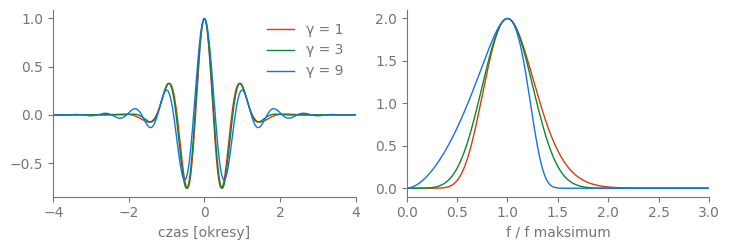

In [15]:
N = 4096
omega = 2*np.pi*np.fft.fftfreq(N)
n = np.arange(N) - N//2
fig, axs = plt.subplots(1, 2, figsize=(7.4, 2.6))
for gamma, kolor in ((1, RDZAWY), (3, ZIELONY), (9, NIEBIESKI)):
    beta = 16/gamma                              # P = 4
    wp = (beta/gamma)**(1/gamma)
    Psi = morse(wp/(2*np.pi*0.02)*omega, beta, gamma)
    psi = np.fft.fftshift(np.fft.ifft(Psi))
    axs[0].plot(n*0.02, psi.real/np.abs(psi).max(), color=kolor, lw=1, label=f"γ = {gamma}")
    axs[1].plot(np.fft.fftfreq(N)[:N//2]/0.02, Psi[:N//2], color=kolor, lw=1)
    q = Psi**2/np.sum(Psi**2)
    sr = np.sum(omega*q); odch = np.sqrt(np.sum((omega - sr)**2*q))
    print(f"gamma = {gamma}: skośność widma {np.sum((omega - sr)**3*q)/odch**3:+.3f}")
axs[0].set_xlim(-4, 4); axs[0].set_xlabel("czas [okresy]"); axs[0].legend(frameon=False)
axs[1].set_xlim(0, 3); axs[1].set_xlabel("f / f maksimum")
fig.tight_layout(); plt.show()
# Najbardziej symetryczne jest widmo dla gamma = 3; dla gamma = 1 ma długi ogon
# ku wysokim częstotliwościom, dla gamma = 9 ku niskim.

### Ćwiczenie 13.3
Dodaj do szeregu El Niño z kodu 13.3 przedłużenie przez odbicie lustrzane zamiast zer. Jak zmienia się skalogram przy brzegach?

### Rozwiązanie 13.3

In [16]:
lata, sst = pywt.data.nino()
x0 = sst - sst.mean()
okresy = np.geomspace(0.75, 16, 133)
zera = np.concatenate([x0, np.zeros(512 - len(x0))])
lustro = np.concatenate([x0, x0[::-1]])[:512]      # odbicie za końcem (i przed początkiem)
moc = [np.abs(cwt(x, 4.0, 1/okresy, 3)[:, :len(x0)])**2 for x in (zera, lustro)]
pasmo = (okresy >= 2) & (okresy <= 7)
for nazwa, m in zip(("zera", "odbicie"), moc):
    e = m[pasmo].mean(axis=0)
    print(f"{nazwa:8s} moc w pasmie 2–7 lat: pierwsze 2 lata {e[:8].mean():.3f}, "
          f"środek {e[100:160].mean():.3f}, ostatnie 2 lata {e[-8:].mean():.3f}")
# Uzupełnienie zerami zaniża moc przy brzegach (falka obejmuje zera); odbicie
# lustrzane zaniża ją mniej, ale tworzy przy brzegu sztuczną symetrię:
# wyniki w odległości mniejszej niż czas trwania falki pozostają niepewne.

zera     moc w pasmie 2–7 lat: pierwsze 2 lata 0.147, środek 0.362, ostatnie 2 lata 0.216
odbicie  moc w pasmie 2–7 lat: pierwsze 2 lata 0.154, środek 0.362, ostatnie 2 lata 0.252


### Ćwiczenie 13.4
Powtórz doświadczenie z kodu 13.4 dla $\beta$ = 5 i 60. Która składowa jest odtwarzana lepiej krótką falką, a która długą, i dlaczego?

### Rozwiązanie 13.4

In [17]:
fs = 400
t, f1, f2, s1, s2 = dwie_skladowe(fs)
czest = np.geomspace(5, 195, 240)
krok = np.log(czest[1]/czest[0])
def pasmo(M, f, d=6):
    k0 = np.rint(np.log(f/czest[0])/krok).astype(int)
    return sum(M[np.clip(k0 + j, 0, len(czest) - 1), np.arange(t.size)]
               for j in range(-d, d + 1))
for beta in (5, 20, 60):
    T = synchro(s1 + s2, fs, czest, beta)[1]
    print(f"beta = {beta:2d}: błąd składowej 1 {100*blad(pasmo(T, f1).real, s1):5.1f}%, "
          f"składowej 2 {100*blad(pasmo(T, f2).real, s2):5.1f}%")
# Składowa 2 (wysoka częstotliwość, wolna zmiana względna) zyskuje na długiej falce.
# Składowa 1 zmienia częstotliwość szybko w stosunku do swojego okresu, więc przy
# beta = 60 falka obejmuje wyraźnie różne częstotliwości i błąd rośnie.

beta =  5: błąd składowej 1   2.2%, składowej 2  18.3%
beta = 20: błąd składowej 1   0.0%, składowej 2   2.3%
beta = 60: błąd składowej 1   1.0%, składowej 2   0.1%


### Ćwiczenie 13.5
Wydziel składowe w kodzie 13.4 wzdłuż grzbietów wyznaczonych funkcją `grzbiet` z kodu 13.5 zamiast wzdłuż znanych krzywych częstotliwości.

### Rozwiązanie 13.5

In [18]:
W, T = synchro(s1 + s2, fs, czest)
granica = np.argmin(np.abs(czest - 60))            # składowe leżą po obu stronach 60 Hz
k1 = grzbiet(W[:granica])
k2 = grzbiet(W[granica:]) + granica
kol = np.arange(t.size)
for nazwa, k0, s in (("składowa 1", k1, s1), ("składowa 2", k2, s2)):
    y = sum(T[np.clip(k0 + j, 0, len(czest) - 1), kol] for j in range(-6, 7)).real
    print(f"{nazwa}: błąd {100*blad(y, s):.1f}%")
# Wyniki są takie same jak przy znanych krzywych częstotliwości: do wydzielenia
# składowych nie trzeba ich znać z góry.

składowa 1: błąd 0.0%
składowa 2: błąd 2.3%


### Ćwiczenie 13.6
Zbadaj, jak błąd grzbietu w kodzie 13.5 zależy od parametru kary (0; 0,05; 0,5; 5; 50) przy odchyleniu szumu równym 1.

### Rozwiązanie 13.6

In [19]:
s = np.cos(2*np.pi*np.cumsum(f2)/fs)
rng = np.random.default_rng(1)
W = cwt(s + 1.0*rng.normal(size=t.size), fs, czest)
for kara in (0, 0.05, 0.5, 5, 50):
    f_dyn = czest[grzbiet(W, kara)]
    print(f"kara {kara:5}: błąd {np.sqrt(np.mean((f_dyn - f2)[200:-200]**2)):5.1f} Hz")
# Bez kary ścieżka jest maksimum w kolumnach. Zbyt duża kara usztywnia ścieżkę,
# która nie nadąża za zmianami częstotliwości; najlepsze są wartości pośrednie.

kara     0: błąd  16.0 Hz
kara  0.05: błąd   6.7 Hz
kara   0.5: błąd   2.8 Hz
kara     5: błąd   2.2 Hz
kara    50: błąd  24.8 Hz


### Ćwiczenie 13.7
Zastąp w superlecie falki Morleta falkami Morse'a o $\gamma = 3$ i czasach trwania proporcjonalnych do kolejnych liczb naturalnych. Porównaj głębokość dołków z wynikami kodu 13.6.

### Rozwiązanie 13.7

In [20]:
def morse_modul(x, fs, czest, P):
    return np.abs(cwt(x, fs, czest, beta=P*P/3, gamma=3))
def superlet_morse(x, fs, czest, P1=3.0, rzad=5):
    return np.exp(sum(np.log(morse_modul(x, fs, czest, P1*i) + 1e-300)
                      for i in range(1, rzad + 1))/rzad)
fs = 1000
t = np.arange(0, 3, 1/fs)
paczka = lambda f0, t0: np.where((t >= t0) & (t < t0 + 7/f0), np.sin(2*np.pi*f0*(t - t0)), 0.0)
x = sum(paczka(f, 1.0) + paczka(f, 1.0 + 11/f) for f in (50, 60))
czest = np.linspace(30, 80, 201)
ia, ib = np.argmin(np.abs(czest - 50)), np.argmin(np.abs(czest - 60))
k0, k1, k2 = int((1 + 3.5/55)*fs), int((1 + 3.5/50)*fs), int((1 + 14.5/50)*fs)
def dolki(S):
    P = S**2
    return (P[ia:ib, k0].min()/min(P[ia, k0], P[ib, k0]),
            P[ia, k1:k2].min()/min(P[ia, k1], P[ia, k2]))
for nazwa, S in (("Morse, P = 9", morse_modul(x, fs, czest, 9)),
                 ("Morse, P = 18", morse_modul(x, fs, czest, 18)),
                 ("superlet Morse'a, P = 3…15", superlet_morse(x, fs, czest, 3.0, 5)),
                 ("superlet Morse'a, P = 4…32", superlet_morse(x, fs, czest, 4.0, 8)),
                 ("superlet Morleta, rząd 5", superlet(x, fs, czest, 3, (5, 5)))):
    d = dolki(S)
    print(f"{nazwa:28s} częstotliwość {d[0]:.2f}, czas {d[1]:.2f}, iloczyn {d[0]*d[1]:.3f}")
# Zasada działa niezależnie od rodziny falek: iloczyn obu miar jest dla zbioru
# falek wyraźnie mniejszy niż dla pojedynczej falki.

Morse, P = 9                 częstotliwość 0.51, czas 0.22, iloczyn 0.111
Morse, P = 18                częstotliwość 0.18, czas 0.65, iloczyn 0.115
superlet Morse'a, P = 3…15   częstotliwość 0.50, czas 0.06, iloczyn 0.032
superlet Morse'a, P = 4…32   częstotliwość 0.21, czas 0.37, iloczyn 0.077
superlet Morleta, rząd 5     częstotliwość 0.39, czas 0.16, iloczyn 0.062


### Ćwiczenie 13.8
Oblicz transformatę WDM impulsu jednostkowego i sinusoidy dla $N_f$ = 8, 64 i 512. Ile współczynników potrzeba w każdym przypadku do zachowania 99% energii?

### Rozwiązanie 13.8

In [21]:
N = 16384
impuls = np.zeros(N); impuls[5000] = 1
sinus = np.cos(2*np.pi*0.1234*np.arange(N))
def ile_na_99(w):
    e = np.sort(w.ravel()**2)[::-1]
    return int(np.searchsorted(np.cumsum(e), 0.99*e.sum()) + 1)
for Nf in (8, 64, 512):
    print(f"Nf = {Nf:3d}: impuls {ile_na_99(wdm(impuls, Nf)):5d}, "
          f"sinusoida {ile_na_99(wdm(sinus, Nf)):5d} współczynników")
# Impuls wypełnia wszystkie pasma w kilku sąsiednich chwilach (kilka razy Nf
# współczynników, bo okno jest rozciągnięte w czasie), sinusoida jedno lub dwa pasma
# we wszystkich chwilach (około N/Nf). Proporcje pikseli dobiera się do sygnału.

Nf =   8: impuls    28, sinusoida  1676 współczynników
Nf =  64: impuls   289, sinusoida   212 współczynników
Nf = 512: impuls  2560, sinusoida    37 współczynników


### Ćwiczenie 13.9
Powtórz obliczenia z kodu 13.10 dla ćwierku, którego częstotliwość rośnie cztery razy wolniej i cztery razy szybciej. Jak zmienia się najlepsza liczba pasm?

### Rozwiązanie 13.9

In [22]:
N = 16384
n = np.arange(N)
def ile(c, udzial=0.99):
    e = np.sort(np.ravel(c)**2)[::-1]
    return int(np.searchsorted(np.cumsum(e), udzial*e.sum()) + 1)
pasma = (8, 16, 32, 64, 128, 256, 512)
print("przyrost częstotliwości  " + "".join(f"{Nf:6d}" for Nf in pasma))
for przyrost in (0.05, 0.2, 0.8):
    x = np.cos(2*np.pi*(0.02*n + przyrost*n**2/(2*N))) if przyrost < 0.5 else \
        np.cos(2*np.pi*(0.02*n + 0.4*n**2/(2*(N/2))))*(n < N/2)
    licz = [ile(wdm(x, Nf)) for Nf in pasma]
    print(f"{przyrost:22.2f}   " + "".join(f"{v:6d}" for v in licz) + f"   najlepiej: {pasma[int(np.argmin(licz))]}")
# Najlepszy prostokąt ma proporcje dopasowane do nachylenia toru sygnału na płaszczyźnie
# czas–częstotliwość: im szybciej rośnie częstotliwość, tym mniej pasm (krótsze prostokąty).

przyrost częstotliwości       8    16    32    64   128   256   512
                  0.05     1786   933   501   272   186   197   309   najlepiej: 128
                  0.20     1942   988   538   369   381   589  1098   najlepiej: 64
                  0.80     1005   535   367   381   590  1112  2167   najlepiej: 32


### Ćwiczenie 13.10
Dodaj do paczki falowej z kodu 13.10 szum biały o odchyleniu 0,2, wyzeruj współczynniki WDM o module mniejszym niż trzy odchylenia szumu i odtwórz sygnał. Porównaj stosunek sygnału do szumu przed i po dla 8, 32 i 128 pasm.

### Rozwiązanie 13.10

In [23]:
N = 16384
n = np.arange(N)
s = np.exp(-((n - 9000)/200)**2)*np.cos(2*np.pi*0.2*n)
z = s + 0.2*np.random.default_rng(0).normal(size=N)
snr = lambda y: 10*np.log10(np.sum(s**2)/np.sum((s - y)**2))
print(f"dane: {snr(z):.1f} dB")
for Nf in (8, 32, 128):
    w = wdm(z, Nf)
    print(f"Nf = {Nf:3d}: po progowaniu {snr(iwdm(np.where(np.abs(w) > 3*0.2, w, 0))):.1f} dB, "
          f"zachowanych współczynników {int(np.sum(np.abs(w) > 0.6))}")
# Baza jest ortonormalna, więc szum ma w każdym współczynniku odchylenie 0,2
# i wystarcza jeden próg. Najlepszy wynik daje liczba pasm, przy której sygnał
# skupia się w najmniejszej liczbie współczynników.

dane: -7.2 dB
Nf =   8: po progowaniu 7.0 dB, zachowanych współczynników 89
Nf =  32: po progowaniu 8.5 dB, zachowanych współczynników 58
Nf = 128: po progowaniu 8.3 dB, zachowanych współczynników 52
